# Fantasy Football Analysis

In [544]:
# Imports
import pandas as pd
from pathlib import Path
import re
import nflreadpy as nfl


In [ ]:
# Project settings: season range and ADP cutoff
START_SEASON = 2015         # 11 years of data (2015-2025)
END_SEASON = 2025
ADP_CUTOFF = 200              # ADP cutoff (~16-17 rounds in a 12-team league) 180-192 players drafted but some are kickers and defenses, so we use ADP 200 to be safe

seasons = list(range(START_SEASON, END_SEASON + 1))

In [546]:
#load ADP data
ADP_DIR = Path("data/raw/adp")

frames = []
for f in sorted(ADP_DIR.glob("adp_ppr_*.csv")):
    season = int(f.stem.split("_")[-1])                 # "adp_ppr_2017" -> 2017
    if season not in seasons:                           # Skip years outside the project range
        continue
    df = pd.read_csv(f)
    df.columns = df.columns.str.strip().str.lower()
    df["season"] = season
    frames.append(df)

adp_raw = pd.concat(frames, ignore_index=True)

# Quick checks: rows per season and which columns showed up
print(adp_raw.groupby("season").size())
print(adp_raw.columns.tolist())
adp_raw.head()

season
2015     461
2016     551
2017     409
2018     485
2019    1038
2020     580
2021     486
2022     346
2023     591
2024     948
2025     981
dtype: int64
['rank', 'player (bye)', 'pos', 'espn', 'sleeper', 'cbs', 'rtsports', 'fantrax', 'avg', 'season', 'real-time']


,rank,player (bye),pos,espn,sleeper,cbs,rtsports,fantrax,avg,season,real-time
0,1,Le'Veon Bell,RB1,NaN,NaN,NaN,1.0,1.0,1.5,2015,NaN
1,2,Adrian Peterson,RB2,NaN,NaN,NaN,2.0,2.0,1.8,2015,NaN
2,3,Antonio Brown,WR1,NaN,NaN,NaN,4.0,4.0,3.8,2015,NaN
3,4,Jamaal Charles,RB3,NaN,NaN,NaN,5.0,3.0,4.0,2015,NaN
4,5,Eddie Lacy,RB4,NaN,NaN,NaN,3.0,5.0,4.0,2015,NaN


In [547]:
# Rename "player (bye)" to "player"
adp_raw = adp_raw.rename(columns={"player (bye)": "player"})

# Every team abbreviation FantasyPros might use, including old ones (OAK, SD, STL) and FA for free agents
TEAMS = ["ARI","ATL","BAL","BUF","CAR","CHI","CIN","CLE","DAL","DEN","DET","GB",
         "HOU","IND","JAC","JAX","KC","LA","LAC","LAR","LV","MIA","MIN","NE","NO",
         "NYG","NYJ","OAK","PHI","PIT","SD","SEA","SF","STL","TB","TEN","WAS","WSH","FA"]

# Pattern: a space, then an optional team code, then an optional "(number)", at the very end of the name
tail_pattern = r"\s+(?:(?:" + "|".join(TEAMS) + r")\s*)?(?:\(\d+\))?\s*$"

adp_raw["player"] = (
    adp_raw["player"]
    .astype(str)
    .str.replace(tail_pattern, "", regex=True)   # Remove team and bye week from player name
    .str.strip()
)

adp_raw[["season", "player", "pos", "avg"]].head(10)

,season,player,pos,avg
0,2015,Le'Veon Bell,RB1,1.5
1,2015,Adrian Peterson,RB2,1.8
2,2015,Antonio Brown,WR1,3.8
3,2015,Jamaal Charles,RB3,4.0
4,2015,Eddie Lacy,RB4,4.0
5,2015,Marshawn Lynch,RB5,7.3
6,2015,Julio Jones,WR2,7.8
7,2015,Dez Bryant,WR3,8.0
8,2015,Rob Gronkowski,TE1,9.0
9,2015,Odell Beckham Jr.,WR4,11.0


In [548]:
# Split position rank, keep skill positions, and apply the ADP cutoff
adp_raw[["position", "pos_adp_rank"]] = adp_raw["pos"].str.extract(r"^([A-Z]+)(\d+)$")
adp_raw["pos_adp_rank"] = pd.to_numeric(adp_raw["pos_adp_rank"])

adp = adp_raw[adp_raw["position"].isin(["QB", "RB", "WR", "TE"])].copy()
adp["adp"] = pd.to_numeric(adp["avg"], errors="coerce")

# Make sure every season's file reaches past the cutoff,
# otherwise that season would be missing late-round players
deepest = adp.groupby("season")["adp"].max()
too_short = deepest[deepest < ADP_CUTOFF]
assert too_short.empty, f"These seasons don't reach ADP {ADP_CUTOFF}: {too_short.to_dict()}"

# Keep players drafted within the first 200 picks (ADP includes K/DST picks)
adp = adp[adp["adp"] <= ADP_CUTOFF]

# Rank among skill players only, after the cutoff
adp["overall_adp_rank"] = adp.groupby("season")["adp"].rank(method="first")

adp = adp[["season", "player", "position", "adp", "overall_adp_rank", "pos_adp_rank"]]
print(adp.groupby("season").size())       # Varies by season

season
2015    188
2016    177
2017    180
2018    192
2019    167
2020    179
2021    173
2022    172
2023    170
2024    170
2025    168
dtype: int64


In [549]:
# Normalize player names into a matching key
import unicodedata
def clean_name(name):
    """Lowercase, remove punctuation and suffixes so names match across sources."""
    name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    name = str(name).lower()
    name = re.sub(r"[.\'\-]", "", name)                 # D.J. -> dj, Le'Veon -> leveon
    name = re.sub(r"\s+(jr|sr|ii|iii|iv|v)$", "", name) # Remove suffixes
    name = re.sub(r"\s+", " ", name).strip()            # Collapse extra spaces
    return name

adp["name_key"] = adp["player"].apply(clean_name)

In [550]:
# load weekly stats for all seasons, then filter to regular season only
weekly_all = nfl.load_player_stats(seasons).to_pandas()
weekly_all = weekly_all[weekly_all["season_type"] == "REG"]     # Regular season only

def season_totals(weekly):
    """Sum weekly stats into one row per player-season."""
    out = (
        weekly.groupby(["season", "player_id", "player_display_name", "position"], as_index=False)
        .agg(ppr_pts=("fantasy_points_ppr", "sum"), games=("week", "nunique"))
    )
    out["ppg"] = out["ppr_pts"] / out["games"]
    out["name_key"] = out["player_display_name"].apply(clean_name)
    return out

season_pts_all = season_totals(weekly_all)                                          # All positions
season_pts = season_totals(weekly_all[weekly_all["position"].isin(["QB", "RB", "WR", "TE"])])  # Skill only

In [551]:
# ADP name_key -> nflreadpy name_key (both already passed through clean_name)
NAME_FIXES = {
    "trenton richardson": "trent richardson",
    "hollywood brown": "marquise brown",
    "chris beanie wells": "chris wells",
    "william fuller": "will fuller",      # " v" suffix is already removed by clean_name
    "robert kelley": "rob kelley",
    "nyheim millerhines": "nyheim hines", # hyphen is already removed by clean_name
    "joshua palmer": "josh palmer",
    "michael vick": "mike vick",
    "charles johnson": "charles d johnson",    # WR; a DE also named Charles Johnson played in 2015
    "tim wright": "timothy wright",

}
adp["name_key"] = adp["player"].apply(clean_name).replace(NAME_FIXES)

In [552]:
# Pass 1: match ADP to season stats on season, name, and position
stat_cols = ["player_id", "ppr_pts", "games", "ppg"]

merged = adp.merge(
    season_pts[["season", "name_key", "position"] + stat_cols],
    on=["season", "name_key", "position"],
    how="left",
)
print(merged["player_id"].isna().sum(), "unmatched after pass 1")  
unmatched = (
    merged.loc[merged["player_id"].isna(), ["season", "player", "position", "adp", "name_key"]]
    .sort_values("adp")
)
unmatched.head(25)

29 unmatched after pass 1


,season,player,position,adp,name_key
546,2018,Le'Veon Bell,RB,2.4,leveon bell
406,2017,Ty Montgomery II,RB,42.0,ty montgomery
796,2019,A.J. Green,WR,64.5,aj green
1836,2025,Travis Hunter,WR,69.8,travis hunter
262,2016,Josh Gordon,WR,76.3,josh gordon
1158,2021,Michael Thomas,WR,79.2,michael thomas
144,2015,Jordy Nelson,WR,89.7,jordy nelson
94,2015,Victor Cruz,WR,99.5,victor cruz
460,2017,Andrew Luck,QB,99.6,andrew luck
1878,2025,Joe Mixon,RB,117.5,joe mixon


In [553]:
# Players whose nflreadpy position differs from their fantasy position.
# Pass 2 only runs for these, so it can't match a missing player to a different person.
POSITION_EXCEPTIONS = {
    (2015, "ty montgomery"),
    (2017, "ty montgomery"),   # Converted WR, listed as WR in nflreadpy
    (2018, "ty montgomery"),
    (2019, "nkeal harry"),     # Listed as TE in nflreadpy
    (2020, "nkeal harry"),
    (2025, "travis hunter"),   # Listed as CB

}

unique_all = season_pts_all.groupby(["season", "name_key"]).filter(lambda g: len(g) == 1)
unique_all = unique_all.rename(columns={"position": "stats_position"})

is_exception = [(s, k) in POSITION_EXCEPTIONS for s, k in zip(merged["season"], merged["name_key"])]
to_retry = merged["player_id"].isna() & pd.Series(is_exception, index=merged.index)

retry = (
    merged.loc[to_retry, ["season", "name_key"]].reset_index()
    .merge(unique_all[["season", "name_key", "stats_position"] + stat_cols],
           on=["season", "name_key"], how="left")
    .set_index("index")
)
merged.loc[to_retry, stat_cols] = retry[stat_cols]

# Show every pass 2 match so each one can be checked by eye
print("Pass 2 matches:")
print(retry[["season", "name_key", "stats_position", "games", "ppr_pts"]].to_string())

leftover = merged[merged["player_id"].isna()]
print(len(leftover), "unmatched after pass 2")    
leftover[["season", "player", "position", "adp"]].sort_values("adp")

Pass 2 matches:
       season       name_key stats_position  games  ppr_pts
index                                                      
163      2015  ty montgomery             WR      6     42.0
406      2017  ty montgomery             WR      8     91.6
668      2018  ty montgomery             WR     13     73.3
896      2019    nkeal harry             TE      7     39.4
1050     2020    nkeal harry             TE     13     73.9
1836     2025  travis hunter             CB      7     63.8
23 unmatched after pass 2


,season,player,position,adp
546,2018,Le'Veon Bell,RB,2.4
796,2019,A.J. Green,WR,64.5
262,2016,Josh Gordon,WR,76.3
1158,2021,Michael Thomas,WR,79.2
144,2015,Jordy Nelson,WR,89.7
94,2015,Victor Cruz,WR,99.5
460,2017,Andrew Luck,QB,99.6
1878,2025,Joe Mixon,RB,117.5
119,2015,Breshad Perriman,WR,126.8
181,2015,Damian Williams,WR,141.0


In [554]:
# Positional finish rank for every drafted player
def rank_vs_position(season, position, pts):
    """1 + number of skill players at that position and season who scored more."""
    pool = season_pts.loc[(season_pts["season"] == season) &
                          (season_pts["position"] == position), "ppr_pts"]
    return (pool > pts).sum() + 1

matched = merged["player_id"].notna()

# Matched players: rank at the position drafters picked them at
# (Travis Hunter is ranked among WRs, not CBs)
merged.loc[matched, "pos_finish_rank"] = [
    rank_vs_position(s, p, pts)
    for s, p, pts in merged.loc[matched, ["season", "position", "ppr_pts"]].itertuples(index=False)
]

# Missed seasons: zero points, ranked last at their position.
# Kept in the data to avoid survivorship bias (drafters still spent the pick)
merged["missed_season"] = ~matched
merged.loc[~matched, ["ppr_pts", "games", "ppg"]] = 0
merged.loc[~matched, "pos_finish_rank"] = [
    rank_vs_position(s, p, -1)    # -1 points, so every player ranks ahead of them
    for s, p in merged.loc[~matched, ["season", "position"]].itertuples(index=False)
]

In [555]:
# Preview merged data
merged.head()

,season,player,position,adp,overall_adp_rank,pos_adp_rank,name_key,player_id,ppr_pts,games,ppg,pos_finish_rank,missed_season
0,2015,Le'Veon Bell,RB,1.5,1.0,1,leveon bell,00-0030496,111.2,6.0,18.533333,47.0,False
1,2015,Adrian Peterson,RB,1.8,2.0,2,adrian peterson,00-0025394,260.7,16.0,16.293750,2.0,False
2,2015,Antonio Brown,WR,3.8,3.0,1,antonio brown,00-0027793,390.2,16.0,24.387500,1.0,False
3,2015,Jamaal Charles,RB,4.0,4.0,3,jamaal charles,00-0026213,101.1,5.0,20.220000,51.0,False
4,2015,Eddie Lacy,RB,4.0,5.0,4,eddie lacy,00-0030485,140.6,15.0,9.373333,32.0,False


In [556]:
# Sanity checks on the merged data
matched = ~merged["missed_season"]

# 1. Players per season (varies under the ADP cutoff, roughly 160 to 185)
print(merged.groupby("season").size())

# 2. Every season covers the full ADP window
print(merged.groupby("season")["adp"].agg(["min", "max"]))     # max just under 200

# 3. Exactly 23 missed seasons
print(merged["missed_season"].sum(), "missed seasons")          # 23

# 4. No player matched to two ADP rows in the same season
dupes = merged[matched].duplicated(subset=["season", "player_id"], keep=False)
print(dupes.sum(), "duplicate matches")                         # 0

# 5. No missing values in the key columns
print(merged[["ppr_pts", "games", "pos_finish_rank"]].isna().sum().sum(), "missing values")   # 0

season
2015    188
2016    177
2017    180
2018    192
2019    167
2020    179
2021    173
2022    172
2023    170
2024    170
2025    168
dtype: int64
        min    max
season            
2015    1.5  199.8
2016    1.0  197.0
2017    1.0  198.0
2018    1.0  198.5
2019    1.0  197.8
2020    1.0  199.7
2021    1.0  200.0
2022    1.0  200.0
2023    1.0  198.8
2024    1.0  199.5
2025    1.0  199.3
23 missed seasons
0 duplicate matches
0 missing values


In [557]:
# Saving the merged data to a CSV file 
Path("data/processed").mkdir(parents=True, exist_ok=True)   # Creates the folder if it doesn't exist

out_path = f"data/processed/adp_vs_actual_{START_SEASON}_{END_SEASON}.csv"
merged.to_csv(out_path, index=False)                         # index=False skips the pandas row numbers

print("Saved to:", out_path)
print(merged.shape)

Saved to: data/processed/adp_vs_actual_2015_2025.csv
(1936, 13)


# 

In [558]:
# Replacement level and points over replacement (POR)
# 12-team PPR league, lineup: 1 QB, 2 RB, 2 WR, 1 TE, 1 FLEX (FLEX split evenly RB/WR)
# Replacement level = points scored by the last starter at each position
REPLACEMENT_RANK = {"QB": 12, "RB": 30, "WR": 30, "TE": 12}

# Uses ALL players (season_pts), not just drafted ones, since waiver pickups can be starters
repl_rows = []
for (season, pos), group in season_pts.groupby(["season", "position"]):
    n = REPLACEMENT_RANK[pos]
    pts_sorted = group["ppr_pts"].sort_values(ascending=False).reset_index(drop=True)
    repl_rows.append({"season": season, "position": pos, "repl_pts": pts_sorted.iloc[n - 1]})

replacement = pd.DataFrame(repl_rows)

# Attach each season-position's replacement level, then compute POR
merged = merged.drop(columns="repl_pts", errors="ignore")    # Safe to rerun
merged = merged.merge(replacement, on=["season", "position"], how="left")
merged["por"] = merged["ppr_pts"] - merged["repl_pts"]


In [559]:
# Sanity checks
# 1. Replacement level by position (averaged across seasons)
print(replacement.groupby("position")["repl_pts"].mean().round(1))

# 2. Share of drafted players who beat replacement, by position
print(merged.groupby("position")["por"].apply(lambda x: (x > 0).mean()).round(2))

# 3. Top 10 player-seasons by POR (should be familiar names)
merged.sort_values("por", ascending=False).head(10)[
    ["season", "player", "position", "adp", "ppr_pts", "repl_pts", "por"]
]

position
QB    271.6
RB    153.1
TE    146.6
WR    187.9
Name: repl_pts, dtype: float64
position
QB    0.40
RB    0.45
TE    0.39
WR    0.38
Name: por, dtype: float64


,season,player,position,adp,ppr_pts,repl_pts,por
738,2019,Christian McCaffrey,RB,2.5,471.2,153.2,318.0
1774,2025,Christian McCaffrey,RB,8.2,416.6,145.4,271.2
194,2016,David Johnson,RB,6.0,407.8,144.6,263.2
1126,2021,Cooper Kupp,WR,46.0,439.5,185.6,253.9
382,2017,Todd Gurley II,RB,18.6,383.3,145.2,238.1
551,2018,Saquon Barkley,RB,6.6,385.8,152.0,233.8
559,2018,Christian McCaffrey,RB,14.8,385.5,152.0,233.5
1769,2025,Bijan Robinson,RB,2.2,370.8,145.4,225.4
1093,2021,Jonathan Taylor,RB,10.4,373.1,148.6,224.5
1771,2025,Jahmyr Gibbs,RB,4.2,366.9,145.4,221.5


In [560]:
# Replacement level by position and season
replacement.pivot(index="season", columns="position", values="repl_pts").round(1)

position,QB,RB,TE,WR
season,,,,
2015,284.5,145.7,160.1,185.7
2016,260.6,144.6,152.3,196.2
2017,255.3,145.2,132.8,171.8
2018,283.1,152.0,130.6,182.5
2019,263.7,153.2,136.0,190.3
2020,282.4,158.1,146.5,191.4
2021,268.4,148.6,159.0,185.6
2022,271.7,158.5,141.2,180.0
2023,262.5,174.5,143.5,206.4


In [ ]:
# Visualization settings
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import FixedLocator

Path("figures").mkdir(exist_ok=True)

#  Shared style for every chart in the project 
POS_ORDER = ["QB", "RB", "WR", "TE"]
POS_COLORS = {"QB": "#ef74a2", "RB": "#8ef2c8", "WR": "#55c9f8", "TE": "#ffac5c"}  
BG = "#05091d"        # figure + background
TEXT = "#e9eefb"      # titles, axis labels, tick labels 
MUTED = "#b1b5c5" #"#39436d"     # tick marks, secondary text
GRID = "#1e2846"     # gridlines + axis lines
AXIS = "#3a4670"     # axis lines and tick marks

# Make every new figure dark by default
plt.rcParams.update({
    "figure.facecolor":  BG,     # area around the plot
    "axes.facecolor":    BG,     # area inside the plot
    "savefig.facecolor": BG,     # keeps the dark background when you save PNGs
    "text.color":        TEXT,   # titles, annotations
    "axes.labelcolor":   TEXT,   # x/y axis labels
    "axes.titlecolor":   TEXT,
    "xtick.color":       MUTED,
    "ytick.color":       MUTED,
    "legend.facecolor":  BG,
    "legend.edgecolor":  GRID,
    "legend.labelcolor": TEXT,
})

def style_axes(ax):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelcolor=TEXT)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


TEAMS = 12   # league size: one round = 12 picks

def round_ticks(ax, axis="x", every=1):
    """Ticks at the end of each round (12, 24, 36, ...) on a draft-slot axis.
    Call after setting the axis limits."""
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    ticks = np.arange(TEAMS, hi + 1, TEAMS)
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_locator(FixedLocator(ticks))
    target.set_tick_params(labelsize=9)
    ax.grid(axis=axis, color=GRID, linewidth=0.6, alpha=0.4)   # faint line at each round break


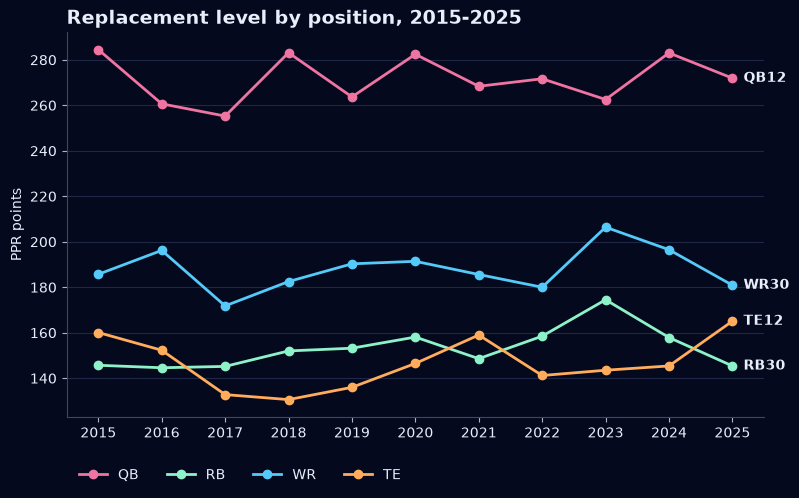

In [589]:
# Visualization: Replacement level by position over time
fig, ax = plt.subplots(figsize=(9, 5))

for pos in POS_ORDER:
    d = replacement[replacement["position"] == pos].sort_values("season")
    ax.plot(d["season"], d["repl_pts"], color=POS_COLORS[pos],
            linewidth=2, marker="o", markersize=6, label=pos)
    # Direct label at the end of each line, so color isn't the only identifier
    last = d.iloc[-1]
    ax.annotate(f"{pos}{REPLACEMENT_RANK[pos]}", xy=(last["season"], last["repl_pts"]),
                xytext=(8, 0), textcoords="offset points", va="center",
                color=TEXT, fontsize=10, fontweight="bold")

ax.set_xticks(seasons)
ax.set_ylabel("PPR points", color=TEXT)
ax.set_title("Replacement level by position, 2015-2025", loc="left",
             fontsize=14, fontweight="bold", color=TEXT)
#ax.text(0, 1.02, "Points scored by the last starter at each position (12-team PPR)",
        #transform=ax.transAxes, color=MUTED, fontsize=10)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.1), ncol=4)
style_axes(ax)
fig.savefig("figures/replacement_level_by_season.png", dpi=200, bbox_inches="tight")
plt.show()



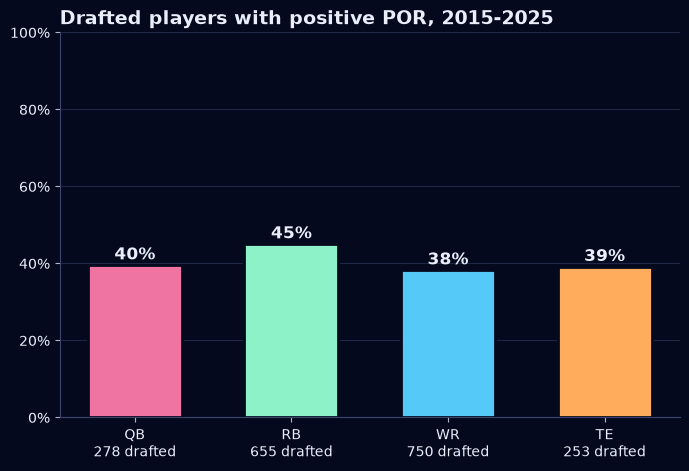

In [607]:
# Visualization: Share of drafted players who beat replacement
beat = (merged.groupby("position")
        .agg(share=("por", lambda x: (x > 0).mean()), n=("por", "size"))
        .loc[POS_ORDER])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(range(len(POS_ORDER)), beat["share"] * 100, width=0.6,
              color=[POS_COLORS[p] for p in POS_ORDER],
              edgecolor= BG, linewidth=2)

# Value label on each bar
for bar, share in zip(bars, beat["share"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{share:.0%}",
            ha="center", color=TEXT, fontsize=12, fontweight="bold")

# Position name plus sample size under each bar
ax.set_xticks(range(len(POS_ORDER)),
              [f"{p}\n{int(n)} drafted" for p, n in zip(POS_ORDER, beat["n"])])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_title("Drafted players with positive POR, 2015-2025", loc="left",
             fontsize=14, fontweight="bold", color=TEXT)
#ax.text(0, 1.02, "Share of drafted players (ADP 1-200) with positive points over replacement, 2015-2025",
        #transform=ax.transAxes, color=MUTED, fontsize=10)
style_axes(ax)
fig.savefig("figures/share_beating_replacement.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# ADP accuracy by position
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Path("figures").mkdir(exist_ok=True)

#  One row per season x position 
rows = []
for (season, pos), g in merged.groupby(["season", "position"]):
    # Spearman: does draft order match finish order? (all drafted players at the position)
    rho, _ = stats.spearmanr(g["pos_adp_rank"], g["pos_finish_rank"])

    # Starters only: players drafted inside the starter range (QB12, RB30, WR30, TE12)
    n_start = REPLACEMENT_RANK[pos]
    starters = g[g["pos_adp_rank"] <= n_start]
    hit_rate = (starters["pos_finish_rank"] <= n_start).mean()            # Finished as a starter?
    mae = (starters["pos_adp_rank"] - starters["pos_finish_rank"]).abs().mean()

    rows.append({"season": season, "position": pos, "n_drafted": len(g),
                 "spearman": rho, "hit_rate": hit_rate, "mae_starters": mae})

acc = pd.DataFrame(rows)



In [592]:
# ---- Summary by position, with 95% CI for the average Spearman ----
summary = acc.groupby("position").agg(
    seasons=("season", "count"),
    spearman_mean=("spearman", "mean"),
    spearman_sd=("spearman", "std"),
    hit_rate=("hit_rate", "mean"),
    mae_starters=("mae_starters", "mean"),
)
t_crit = stats.t.ppf(0.975, df=summary["seasons"] - 1)
margin = t_crit * summary["spearman_sd"] / np.sqrt(summary["seasons"])
summary["ci_low"] = summary["spearman_mean"] - margin
summary["ci_high"] = summary["spearman_mean"] + margin

order = ["QB", "RB", "WR", "TE"]
print(summary.loc[order].round(3))



          seasons  spearman_mean  spearman_sd  hit_rate  mae_starters  ci_low  \
position                                                                        
QB             11          0.385        0.187     0.591         9.280   0.260   
RB             11          0.537        0.140     0.670        17.109   0.443   
WR             11          0.545        0.098     0.639        21.630   0.479   
TE             11          0.400        0.136     0.568        10.174   0.309   

          ci_high  
position           
QB          0.511  
RB          0.631  
WR          0.611  
TE          0.491  


* RB and WR draft order matches finish order moderately well (about 0.54), and WR is the most consistent year to year (the shortest box).
* QB is the least predictable and the most volatile. One season had a correlation near 0.04, meaning QB ADP that year was barely better than random. Worth finding out which year (code below), because it makes a great slide anecdote.
* TE is similarly weak, which fits the common fantasy saying that the TE position is “a few elite guys and then chaos.”

Two cautions for your modeling-choices slide

1. Lower Spearman for QB and TE is partly mechanical. Far fewer QBs and TEs get drafted than RBs and WRs, and QB scores bunch closely together. When everyone in a group is similar, small point differences shuffle the ranks a lot. Think of ranking a class where everyone scored between 88 and 92: the order looks random even if the test is fine. Hit rate is the fairer cross-position comparison, and it tells the same story, just more gently.

2. Rank error isn’t comparable across positions as-is. WR’s 21.6 looks worst, but WR has 30 starter slots and QB only 12. Divide by the number of starters to compare:

QB: 9.3 / 12 = 0.77
TE: 10.2 / 12 = 0.85
RB: 17.1 / 30 = 0.57
WR: 21.6 / 30 = 0.72

In [608]:
# Is ADP more accurate for RB/WR than QB/TE?
wide = acc.pivot(index="season", columns="position", values="spearman")

rb_wr = wide[["RB", "WR"]].mean(axis=1)
qb_te = wide[["QB", "TE"]].mean(axis=1)
diff = rb_wr - qb_te

t_stat, p_t = stats.ttest_rel(rb_wr, qb_te)    # Paired t-test (same seasons)
p_w = stats.wilcoxon(diff).pvalue               # Non-parametric check, safer with 11 seasons

print(f"Average gap (RB/WR minus QB/TE): {diff.mean():.3f}")
print(f"RB/WR more accurate in {(diff > 0).sum()} of {len(diff)} seasons")
print(f"Paired t-test p = {p_t:.4f} | Wilcoxon p = {p_w:.4f}")

# Which seasons was QB ADP least accurate?
print(acc[acc["position"] == "QB"].sort_values("spearman").head(11)[["season", "spearman", "hit_rate"]])

Average gap (RB/WR minus QB/TE): 0.148
RB/WR more accurate in 9 of 11 seasons
Paired t-test p = 0.0173 | Wilcoxon p = 0.0137
    season  spearman  hit_rate
40    2025  0.040000  0.583333
32    2023  0.238261  0.583333
16    2019  0.270435  0.583333
36    2024  0.315385  0.583333
4     2016  0.339130  0.500000
8     2017  0.349802  0.500000
0     2015  0.374416  0.500000
20    2020  0.463932  0.750000
12    2018  0.507937  0.583333
28    2022  0.620000  0.500000
24    2021  0.721026  0.833333


In [609]:
print(acc[acc["position"] == "WR"].sort_values("spearman").head(11)[["season", "spearman", "hit_rate"]])

    season  spearman  hit_rate
7     2016  0.414862  0.600000
27    2021  0.425430  0.600000
19    2019  0.453437  0.666667
43    2025  0.492496  0.633333
11    2017  0.514176  0.666667
39    2024  0.536021  0.600000
23    2020  0.536144  0.600000
31    2022  0.611362  0.700000
35    2023  0.643387  0.633333
3     2015  0.656940  0.633333
15    2018  0.708358  0.700000


In [610]:
print(acc[acc["position"] == "RB"].sort_values("spearman").head(11)[["season", "spearman", "hit_rate"]])

    season  spearman  hit_rate
5     2016  0.290071  0.566667
13    2018  0.355926  0.533333
1     2015  0.390481  0.500000
9     2017  0.529267  0.633333
33    2023  0.539635  0.700000
21    2020  0.562975  0.666667
37    2024  0.576190  0.766667
25    2021  0.588243  0.733333
29    2022  0.653194  0.733333
41    2025  0.687951  0.733333
17    2019  0.735805  0.800000


In [611]:
print(acc[acc["position"] == "TE"].sort_values("spearman").head(11)[["season", "spearman", "hit_rate"]])

    season  spearman  hit_rate
42    2025  0.212874  0.416667
10    2017  0.242095  0.500000
18    2019  0.303360  0.500000
14    2018  0.305217  0.666667
30    2022  0.335968  0.666667
38    2024  0.386787  0.583333
2     2015  0.401709  0.666667
22    2020  0.487998  0.500000
34    2023  0.546753  0.583333
26    2021  0.561898  0.583333
6     2016  0.616522  0.583333


Both tests agree (p ≈ 0.017 and 0.014), so the claim holds: ADP is significantly more accurate for RBs and WRs than for QBs and TEs, and the gap held in 9 of 11 seasons. 

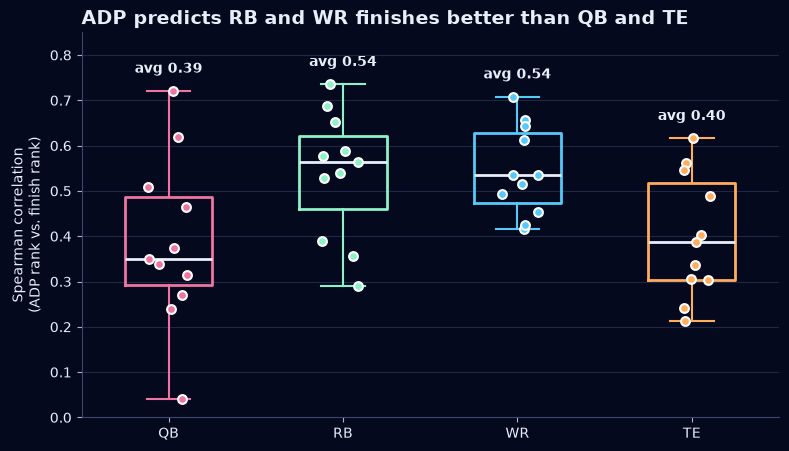

In [594]:
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(0)     # Fixed seed so the dot jitter looks the same every run

for i, pos in enumerate(POS_ORDER):
    vals = acc.loc[acc["position"] == pos, "spearman"]
    # Box: light outline in the position color
    ax.boxplot(vals, positions=[i], widths=0.5, showfliers=False,
               boxprops=dict(color=POS_COLORS[pos], linewidth=2),
               whiskerprops=dict(color=POS_COLORS[pos], linewidth=1.5),
               capprops=dict(color=POS_COLORS[pos], linewidth=1.5),
               medianprops=dict(color=TEXT, linewidth=2))
    # One dot per season
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, s=40,
               color=POS_COLORS[pos], edgecolor="white", linewidth=1.5, zorder=3)
    # Average label above each box
    ax.text(i, vals.max() + 0.04, f"avg {vals.mean():.2f}", ha="center",
            color=TEXT, fontsize=10, fontweight="bold")

ax.set_xticks(range(len(POS_ORDER)), POS_ORDER)
ax.set_ylim(0, 0.85)
ax.set_ylabel("Spearman correlation\n(ADP rank vs. finish rank)", color=TEXT)
ax.set_title("ADP predicts RB and WR finishes better than QB and TE", loc="left",
             fontsize=14, fontweight="bold", color=TEXT)
style_axes(ax)
fig.savefig("figures/adp_accuracy_by_position.png", dpi=200, bbox_inches="tight")
plt.show()

In [595]:
qb25 = merged[(merged["season"] == 2025) & (merged["position"] == "QB")]
qb25.assign(miss=qb25["pos_finish_rank"] - qb25["pos_adp_rank"]) \
    .sort_values("miss", key=abs, ascending=False).head(5)[
    ["player", "pos_adp_rank", "pos_finish_rank", "miss", "games"]]

,player,pos_adp_rank,pos_finish_rank,miss,games
1796,Jayden Daniels,3,34.0,31.0,7.0
1850,Kyler Murray,9,38.0,29.0,5.0
1799,Joe Burrow,4,29.0,25.0,8.0
1924,Matthew Stafford,23,3.0,-20.0,17.0
1790,Lamar Jackson,2,20.0,18.0,13.0


In [597]:
# Value curve, POR by ADP for each position
from statsmodels.nonparametric.smoothers_lowess import lowess

PICKS = np.arange(1, ADP_CUTOFF + 1)   # Picks 1 to 200
FRAC = 0.4                             # Share of points LOWESS uses for each local fit
N_BOOT = 2000                          # Bootstrap resamples
MIN_COVERAGE = 0.9                     # Show band only where 90%+ of bootstrap curves exist

def fit_curve(df):
    """LOWESS fit of POR on ADP (no outlier downweighting), evaluated on picks 1-200."""
    fit = lowess(df["por"], df["adp"], frac=FRAC, it=0)    # it=0 keeps busts and breakouts at full weight
    xs, idx = np.unique(fit[:, 0], return_index=True)      # Interpolation needs unique x values
    return np.interp(PICKS, xs, fit[idx, 1], left=np.nan, right=np.nan)

rng = np.random.default_rng(42)
season_list = merged["season"].unique()
curves, bands = {}, {}

for pos in POS_ORDER:
    d = merged[merged["position"] == pos]
    curves[pos] = fit_curve(d)
    by_season = {s: g for s, g in d.groupby("season")}    # Split once, reuse in every resample

    # Bootstrap: resample whole seasons with replacement, refit, repeat N_BOOT times
    boots = np.array([
        fit_curve(pd.concat([by_season[s] for s in rng.choice(season_list, size=len(season_list), replace=True)
                             if s in by_season]))
        for _ in range(N_BOOT)
    ])

    # Mask picks where too few bootstrap curves have data
    coverage = np.mean(~np.isnan(boots), axis=0)
    lower = np.nanpercentile(boots, 2.5, axis=0)
    upper = np.nanpercentile(boots, 97.5, axis=0)
    lower[coverage < MIN_COVERAGE] = np.nan
    upper[coverage < MIN_COVERAGE] = np.nan
    bands[pos] = (lower, upper)

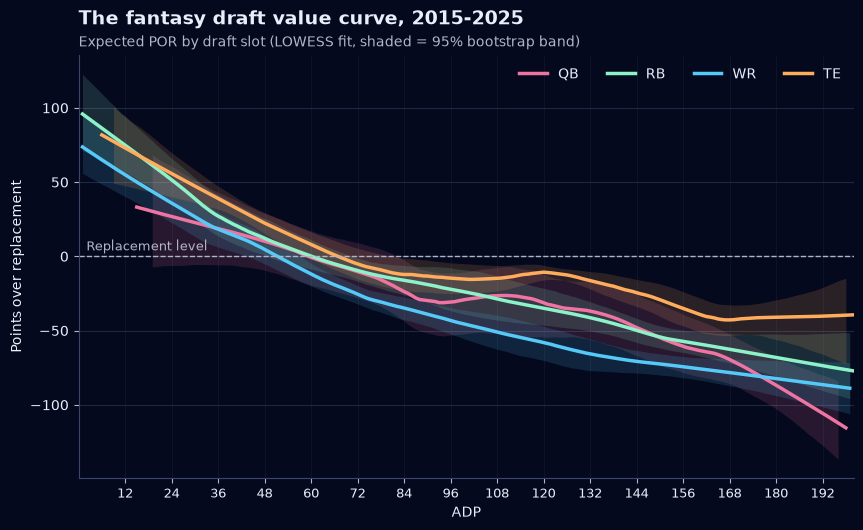

In [618]:
# All four value curves together 
fig, ax = plt.subplots(figsize=(10, 5.5))
LABEL_NUDGE = {"QB": 0, "RB": 6, "WR": -6, "TE": 0}    # Spreads out end labels that sit close together

for pos in POS_ORDER:
    ax.fill_between(PICKS, *bands[pos], color=POS_COLORS[pos], alpha=0.15, linewidth=0)
    ax.plot(PICKS, curves[pos], color=POS_COLORS[pos], linewidth=2.5, label=pos)
    # Direct label at the right end of each curve
    #last = np.where(~np.isnan(curves[pos]))[0][-1]
    #ax.text(PICKS[last] + 3, curves[pos][last] + LABEL_NUDGE[pos], pos,
    #        color=TEXT, fontsize=11, fontweight="bold", va="center", clip_on=False)

ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
ax.text(2, 4, "Replacement level", ha="left", color=MUTED, fontsize=9)
ax.set_xlim(0, ADP_CUTOFF)
round_ticks(ax)
style_axes(ax)
ax.set_xlabel("ADP", color=TEXT)
ax.set_ylabel("Points over replacement", color=TEXT)
ax.set_title("The fantasy draft value curve, 2015-2025", loc="left", pad=22,
             fontsize=14, fontweight="bold", color=TEXT)
ax.text(0, 1.02, "Expected POR by draft slot (LOWESS fit, shaded = 95% bootstrap band)",
        transform=ax.transAxes, color=MUTED, fontsize=10)
ax.legend(frameon=False, loc="upper right", ncol=4)
style_axes(ax)
fig.savefig("figures/value_curve_by_position.png", dpi=200, bbox_inches="tight")
plt.show()

In [622]:
# Spline value curves by position, with season bootstrap bands
import statsmodels.formula.api as smf

KNOT_STEP = 24                          # Knot every 2 rounds (fewer knots = less wiggle per position)
rng = np.random.default_rng(42)         # Reset so this bootstrap is reproducible on its own

def fit_spline_curve(df):
    """Cubic regression spline of POR on ADP, evaluated on PICKS (NaN outside the data range)."""
    lo, hi = df["adp"].min(), df["adp"].max()
    knots = [k for k in range(KNOT_STEP, ADP_CUTOFF, KNOT_STEP) if lo + 5 < k < hi - 5]  # Keep knots inside the data
    model = smf.ols(f"por ~ cr(adp, knots={knots}, constraints='center')", data=df).fit()
    out = np.full(len(PICKS), np.nan)
    inside = (PICKS >= lo) & (PICKS <= hi)                  # Spline can't predict outside its data
    out[inside] = model.predict(pd.DataFrame({"adp": PICKS[inside]})).to_numpy()
    return out, model.rsquared

spline_curves, spline_bands, spline_r2 = {}, {}, {}

for pos in POS_ORDER:
    d = merged[merged["position"] == pos]
    spline_curves[pos], spline_r2[pos] = fit_spline_curve(d)
    by_season = {s: g for s, g in d.groupby("season")}

    # Bootstrap: resample whole seasons with replacement, refit, repeat N_BOOT times
    boots = np.array([
        fit_spline_curve(pd.concat([by_season[s] for s in rng.choice(season_list, size=len(season_list), replace=True)
                                    if s in by_season]))[0]
        for _ in range(N_BOOT)
    ])

    # Mask picks where too few bootstrap curves have data
    coverage = np.mean(~np.isnan(boots), axis=0)
    lower = np.nanpercentile(boots, 2.5, axis=0)
    upper = np.nanpercentile(boots, 97.5, axis=0)
    lower[coverage < MIN_COVERAGE] = np.nan
    upper[coverage < MIN_COVERAGE] = np.nan
    spline_bands[pos] = (lower, upper)

print("Spline R-squared by position:", {p: round(r, 3) for p, r in spline_r2.items()})

/Users/daniel.vazquez/Documents/advanced football analytics/Fantasy-Football-Analysis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/daniel.vazquez/Documents/advanced football analytics/Fantasy-Football-Analysis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Spline R-squared by position: {'QB': np.float64(0.172), 'RB': np.float64(0.311), 'WR': np.float64(0.314), 'TE': np.float64(0.242)}


/Users/daniel.vazquez/Documents/advanced football analytics/Fantasy-Football-Analysis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


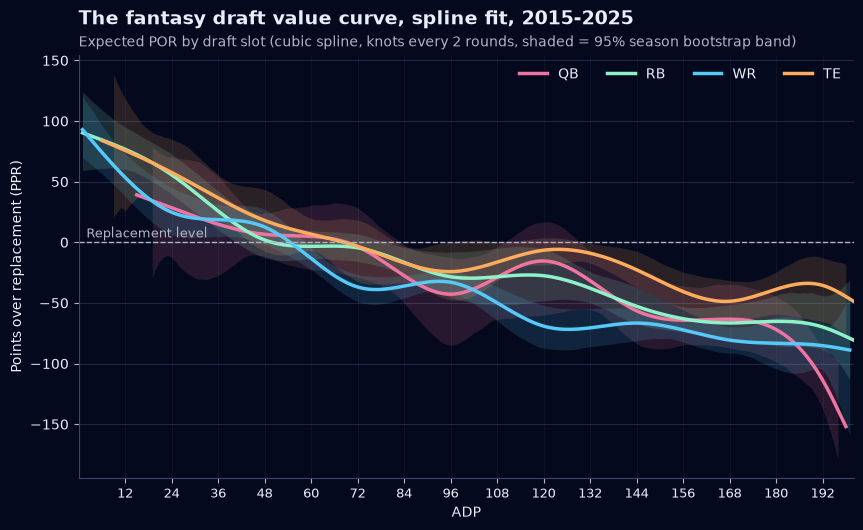

In [623]:
# Spline value curves, all four positions
fig, ax = plt.subplots(figsize=(10, 5.5))
for pos in POS_ORDER:
    ax.fill_between(PICKS, *spline_bands[pos], color=POS_COLORS[pos], alpha=0.15, linewidth=0)
    ax.plot(PICKS, spline_curves[pos], color=POS_COLORS[pos], linewidth=2.5, label=pos)

ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
ax.text(2, 4, "Replacement level", ha="left", color=MUTED, fontsize=9)
ax.set_xlim(0, ADP_CUTOFF)
round_ticks(ax)
ax.set_xlabel("ADP")
ax.set_ylabel("Points over replacement (PPR)")
ax.set_title("The fantasy draft value curve, spline fit, 2015-2025", loc="left", pad=22,
             fontsize=14, fontweight="bold")
ax.text(0, 1.02, "Expected POR by draft slot (cubic spline, knots every 2 rounds, shaded = 95% season bootstrap band)",
        transform=ax.transAxes, color=MUTED, fontsize=10)
ax.legend(frameon=False, loc="upper right", ncol=4)
style_axes(ax)
fig.savefig("figures/value_curve_by_position_spline.png", dpi=200, bbox_inches="tight")
plt.show()

QB: LOESS drop =    nan | spline drop =    nan
RB: LOESS drop =   74.7 | spline drop =   80.0
WR: LOESS drop =   66.8 | spline drop =   66.8
TE: LOESS drop =   65.0 | spline drop =   69.1


95% band is how much the average POR at each pick shift if i had drawn different seasons

In [ ]:
# How fast does value fall? Expected POR at pick 12 (end of round 1) vs. pick 60 (end of round 5)
for pos in POS_ORDER:
    v12, v60 = curves[pos][11], curves[pos][59]
    print(f"{pos}: pick 12 = {v12:6.1f} | pick 60 = {v60:6.1f} | drop = {v12 - v60:6.1f}")



QB: pick 12 =    nan | pick 60 =    7.6 | drop =    nan
RB: pick 12 =   83.1 | pick 60 =    1.2 | drop =   82.0
WR: pick 12 =   61.2 | pick 60 =  -10.0 | drop =   71.2
TE: pick 12 =   74.3 | pick 60 =    8.0 | drop =   66.3


In [ ]:
# How fast does value fall? Expected POR at pick 24 (end of round 2) vs. pick 72 (end of round 6)
for pos in POS_ORDER:
    v24, v72 = curves[pos][23], curves[pos][71]
    print(f"{pos}: pick 24 = {v24:6.1f} | pick 72 = {v72:6.1f} | drop = {v24 - v72:6.1f}")

QB: pick 24 =   39.3 | pick 72 =    1.7 | drop =   37.6
RB: pick 24 =   55.5 | pick 72 =   -8.8 | drop =   64.3
WR: pick 24 =   41.5 | pick 72 =  -24.5 | drop =   65.9
TE: pick 24 =   56.3 | pick 72 =   -4.7 | drop =   61.0


In [ ]:
# 2. Average POR by draft round (12 picks per round), hiding cells with fewer than 5 players
merged["round"] = ((merged["adp"] - 1) // 12 + 1).astype(int)
early = merged[merged["round"] <= 10]
por_by_round = early.pivot_table(index="round", columns="position", values="por", aggfunc="mean")[POS_ORDER]
n_by_round = early.pivot_table(index="round", columns="position", values="por", aggfunc="size")[POS_ORDER]
print(por_by_round.where(n_by_round >= 5).round(1))

position    QB    RB    WR    TE
round                           
1          NaN  86.6  75.0   NaN
2         35.3  61.3  31.6  63.2
3          5.6  38.3  22.3  58.8
4         18.6  13.0   5.7  13.9
5          2.7   2.2   5.9  15.9
6         15.8  -0.3 -24.8  -1.0
7        -39.6 -25.8 -42.8 -13.7
8        -21.1 -21.3 -33.3 -31.7
9        -62.1 -27.5 -34.9  -1.5
10       -10.4 -17.8 -70.6  -9.1


1. Early RBs are the most valuable picks, and RB value falls fastest.
Round 1 RBs averaged +86.6 POR vs. +75.0 for WRs, and the RB curve drops the most from pick 12 to pick 60 (82 points vs. 71 for WR). Elite RBs win leagues, but the advantage disappears quickly.

2. RBs lose value fastest at the very top of the draft (round 1). After that, RB, WR and TE values decline at similar rates, and QB value declines about half as fast, which is why waiting on a QB works.

3. WRs fall below replacement first.
The WR curve crosses zero around pick 52, before every other position, and stays the lowest from about pick 75 onward. Late-round WRs rarely turn into starters, so the WR pool thins out early.

4. The best value gap is TE in rounds 2 and 3.
Round 3 TEs averaged +58.8 POR, vs. +38.3 for RBs and +22.3 for WRs at the same picks. When an elite TE is available, the market underprices him relative to the other positions. Caveat for the slide: fewer TEs go in round 3, so this cell is based on a smaller sample.

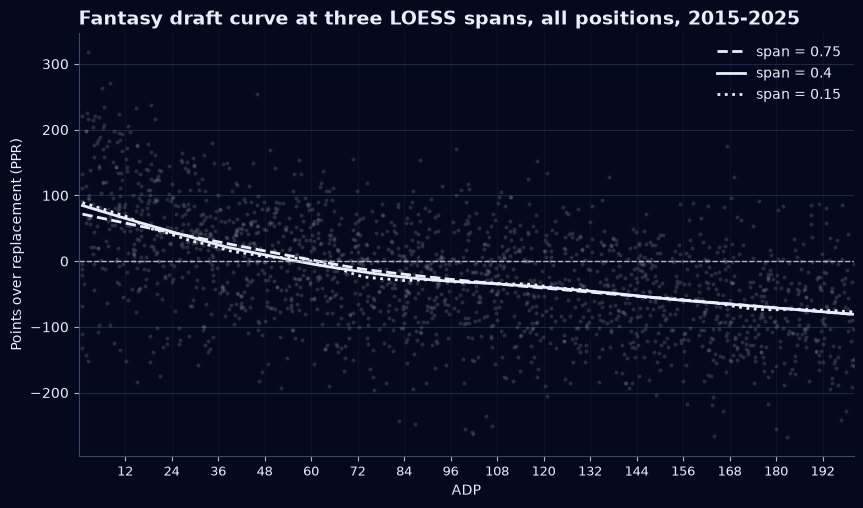

/var/folders/mf/fq9r7w_j3t9fv4n1ym5_581r0000gn/T/ipykernel_57649/647906389.py:27: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_spline = smf.ols("por ~ cr(adp, knots=KNOTS)", data=merged).fit()


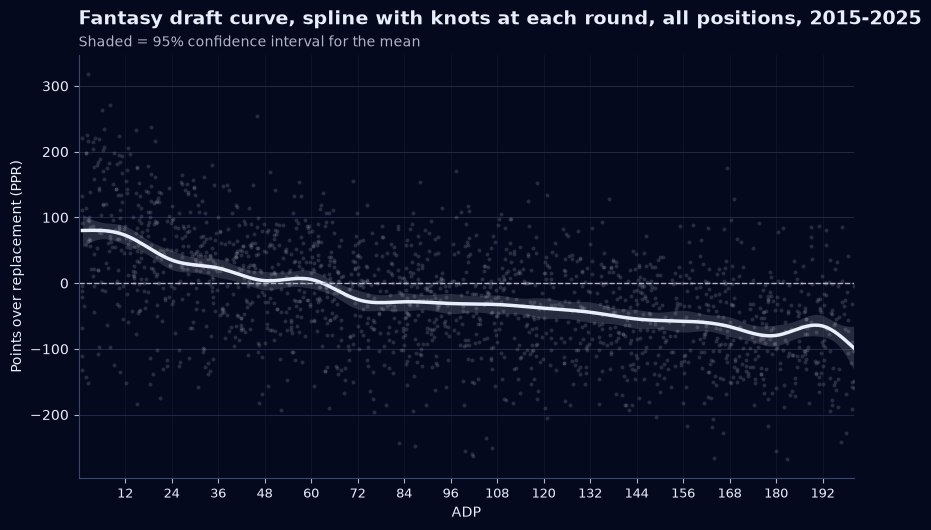

Spline R-squared: 0.271
Expected POR at picks 1, 12, 24, 36, 48, 60, 72, 84, 96, 108: [80.1, 72.9, 35.2, 23.0, 3.8, 5.6, -24.9, -28.4, -31.0, -32.5]


In [625]:
# Overall fantasy draft curve
# LOESS at several spans, and a spline with knots at the end of each fantasy round
import statsmodels.formula.api as smf

SPANS = {0.75: "--", 0.4: "-", 0.15: ":"}      # Span -> line style (color stays neutral; color means position elsewhere)
KNOTS = list(range(12, ADP_CUTOFF, 12))        # End of each 12-team round: 12, 24, ..., 192

# Chart 1: LOESS span sensitivity 
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(merged["adp"], merged["por"], s=8, color=MUTED, alpha=0.2, linewidth=0)
for span, style in SPANS.items():
    fit = lowess(merged["por"], merged["adp"], frac=span, it=0)   # it=0 to match the position curves
    ax.plot(fit[:, 0], fit[:, 1], color=TEXT, linestyle=style, linewidth=2, label=f"span = {span}")
ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
ax.set_xlim(0, ADP_CUTOFF)
round_ticks(ax)
ax.set_xlabel("ADP")
ax.set_ylabel("Points over replacement (PPR)")
ax.set_title("Fantasy draft curve at three LOESS spans, all positions, 2015-2025",
             loc="left", fontsize=14, fontweight="bold")
ax.legend(frameon=False, loc="upper right")
style_axes(ax)
fig.savefig("figures/overall_draft_curve_loess_spans.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 2: Spline with knots at the end of each round 
fit_spline = smf.ols("por ~ cr(adp, knots=KNOTS)", data=merged).fit()
pred = fit_spline.get_prediction(pd.DataFrame({"adp": PICKS})).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(merged["adp"], merged["por"], s=8, color=MUTED, alpha=0.2, linewidth=0)
ax.fill_between(PICKS, pred["mean_ci_lower"], pred["mean_ci_upper"], color=TEXT, alpha=0.15, linewidth=0)
ax.plot(PICKS, pred["mean"], color=TEXT, linewidth=2.5)
ax.axhline(0, color=MUTED, linewidth=1, linestyle="--")
ax.set_xlim(0, ADP_CUTOFF)
round_ticks(ax)                                  # Round gridlines double as the knot locations
ax.set_xlabel("ADP")
ax.set_ylabel("Points over replacement (PPR)")
ax.set_title("Fantasy draft curve, spline with knots at each round, all positions, 2015-2025",
             loc="left", fontsize=14, fontweight="bold", pad = 22)
ax.text(0, 1.02, "Shaded = 95% confidence interval for the mean", transform=ax.transAxes,
        color=MUTED, fontsize=10)
style_axes(ax)
fig.savefig("figures/overall_draft_curve_spline.png", dpi=200, bbox_inches="tight")
plt.show()

# How much does draft slot explain? 
print(f"Spline R-squared: {fit_spline.rsquared:.3f}")
print(f"Expected POR at picks 1, 12, 24, 36, 48, 60, 72, 84, 96, 108: "
      f"{pred['mean'].iloc[[0, 11, 23, 35, 47, 59, 71, 83, 95, 107]].round(1).tolist()}")

In [627]:
# LOESS vs spline: expected POR at pick 12 and pick 60
for pos in POS_ORDER:
    l12, l60 = curves[pos][11], curves[pos][59]
    s12, s60 = spline_curves[pos][11], spline_curves[pos][59]
    print(f"{pos}: LOESS drop = {l12 - l60:6.1f} | spline drop = {s12 - s60:6.1f}")

QB: LOESS drop =    nan | spline drop =    nan
RB: LOESS drop =   74.7 | spline drop =   80.0
WR: LOESS drop =   66.8 | spline drop =   66.8
TE: LOESS drop =   65.0 | spline drop =   69.1


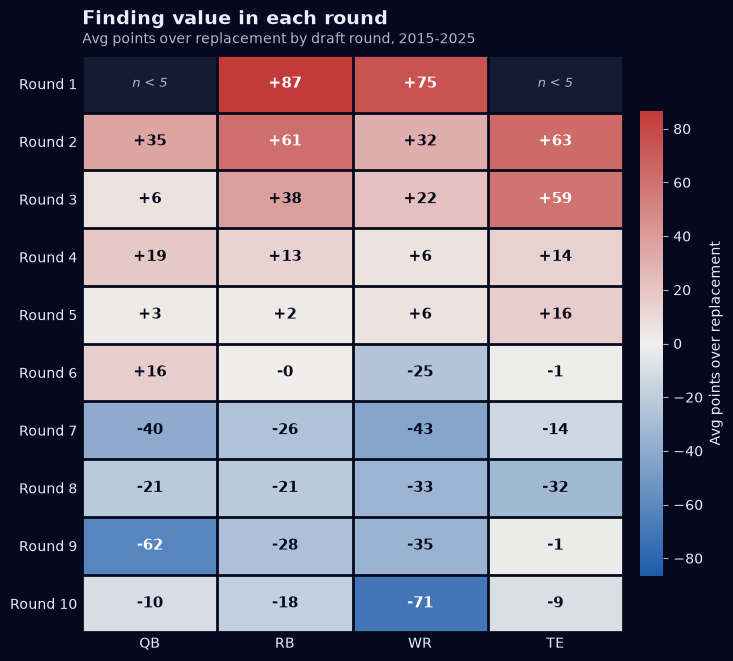

In [612]:
# Heatmap of average POR by draft round and position
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Diverging scale: blue (below replacement) -> light gray (at replacement) -> red (above)
DIVERGING = LinearSegmentedColormap.from_list("por_div", ["#1c5cab", "#f0efec", "#c23b3a"])
cmap = DIVERGING.copy()
cmap.set_bad("#141b33")                       # Color for hidden (n < 5) cells

table = por_by_round.where(n_by_round >= 5)    # Hide cells with fewer than 5 players
vmax = np.nanmax(np.abs(table.values))
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)   # 0 = replacement sits in the middle

def text_color_for(value):
    """Dark text on bright cells, white text on dark cells, based on the cell's actual color."""
    r, g, b, _ = cmap(norm(value))
    brightness = 0.2126 * r + 0.7152 * g + 0.0722 * b    # Perceived brightness (0 = black, 1 = white)
    return BG if brightness > 0.55 else "white"

fig, ax = plt.subplots(figsize=(7.5, 7.5))
im = ax.imshow(np.ma.masked_invalid(table.values), cmap=cmap, norm=norm, aspect="auto")

# BG color for gaps between cells
ax.set_xticks(np.arange(-0.5, len(POS_ORDER)), minor=True)
ax.set_yticks(np.arange(-0.5, len(table)), minor=True)
ax.grid(which="minor", color= BG, linewidth=2)
ax.tick_params(which="minor", length=0)

# Number in every cell, with text color matched to the cell's brightness
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.iloc[i, j]
        if np.isnan(v):
            ax.text(j, i, "n < 5", ha="center", va="center", color=MUTED, fontsize=9, style="italic")
        else:
            ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=11, fontweight="bold",
                    color=text_color_for(v))

ax.set_xticks(range(len(POS_ORDER)), POS_ORDER)
ax.set_yticks(range(len(table)), [f"Round {r}" for r in table.index])
ax.tick_params(length=0, labelcolor=TEXT)
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
cbar.set_label("Avg points over replacement", color=TEXT)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=MUTED, labelcolor=TEXT)

ax.set_title("Finding value in each round", loc="left", pad=22,
             fontsize=14, fontweight="bold", color=TEXT)
ax.text(0, 1.02, "Avg points over replacement by draft round, 2015-2025",
        transform=ax.transAxes, color=MUTED, fontsize=10)
fig.savefig("figures/por_by_round_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Bust and breakout rates

from matplotlib.patches import Patch

# Availability: share of the season's games played 
merged["season_games"] = np.where(merged["season"] >= 2021, 17, 16)   # 17-game seasons began in 2021
merged["games_pct"] = merged["games"] / merged["season_games"]

# Starter status: drafted as one? finished as one? 
merged["n_start"] = merged["position"].map(REPLACEMENT_RANK)
merged["drafted_starter"] = merged["pos_adp_rank"] <= merged["n_start"]
merged["finished_starter"] = merged["pos_finish_rank"] <= merged["n_start"]

merged["bust"] = merged["drafted_starter"] & ~merged["finished_starter"]
merged["breakout"] = ~merged["drafted_starter"] & merged["finished_starter"]


# Missed time = missed 4+ games, the minimum stay on NFL injured reserve (IR)
MISSED_GAMES_CUTOFF = 4
merged["games_missed"] = merged["season_games"] - merged["games"]
merged["bust_type"] = np.select(
    [merged["bust"] & (merged["games_missed"] >= MISSED_GAMES_CUTOFF), merged["bust"]],
    ["missed time", "played, underperformed"],
    default="",
)

# Summary by position 
rows = []
for pos in POS_ORDER:
    g = merged[merged["position"] == pos]
    starters, others = g[g["drafted_starter"]], g[~g["drafted_starter"]]
    rows.append({
        "position": pos,
        "drafted_starters": len(starters),
        "bust_rate": starters["bust"].mean(),
        "bust_missed_time": (starters["bust_type"] == "missed time").mean(),
        "bust_underperformed": (starters["bust_type"] == "played, underperformed").mean(),
        "drafted_non_starters": len(others),
        "breakouts": others["breakout"].sum(),
        "breakout_rate": others["breakout"].mean(),
    })
bust_summary = pd.DataFrame(rows).set_index("position")
print(bust_summary.round(3))

          drafted_starters  bust_rate  bust_missed_time  bust_underperformed  \
position                                                                       
QB                     132      0.409             0.242                0.167   
RB                     330      0.330             0.239                0.091   
WR                     330      0.361             0.218                0.142   
TE                     132      0.432             0.280                0.152   

          drafted_non_starters  breakouts  breakout_rate  
position                                                  
QB                         146         42          0.288  
RB                         325         82          0.252  
WR                         420         85          0.202  
TE                         121         31          0.256  


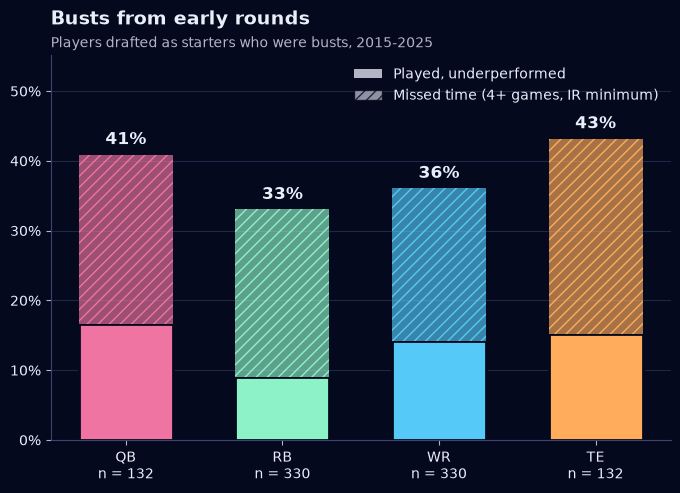

In [616]:
# Bust rate by position, split by cause
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(POS_ORDER))
colors = [POS_COLORS[p] for p in POS_ORDER]
under = bust_summary["bust_underperformed"] * 100
missed = bust_summary["bust_missed_time"] * 100

# Solid = played but underperformed;
ax.bar(x, under, width=0.6, color=colors, edgecolor= BG, linewidth=2)

# hatched = missed time
ax.bar(x, missed, bottom=under, width=0.6, color=[to_rgba(c, 0.65) for c in colors],
       hatch="///", edgecolor= colors, linewidth=0)

# Total bust rate above each bar
for xi, total in zip(x, under + missed):
    ax.text(xi, total + 1.5, f"{total:.0f}%", ha="center", color=TEXT,
            fontsize=12, fontweight="bold")

ax.set_xticks(x, [f"{p}\nn = {n}" for p, n in zip(POS_ORDER, bust_summary["drafted_starters"])])
ax.set_ylim(0, max(under + missed) + 12)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.legend(handles=[Patch(facecolor=MUTED, label="Played, underperformed"),
                   Patch(facecolor=MUTED, alpha=0.80, hatch="///", edgecolor= BG,
                         label="Missed time (4+ games, IR minimum)")],
          frameon=False, loc="upper right")
ax.set_title("Busts from early rounds", loc="left", pad=22,
             fontsize=14, fontweight="bold", color=TEXT)
ax.text(0, 1.02, "Players drafted as starters who were busts, 2015-2025",
        transform=ax.transAxes, color=MUTED, fontsize=10)
style_axes(ax)
fig.savefig("figures/bust_rate_by_cause.png", dpi=200, bbox_inches="tight")
plt.show()

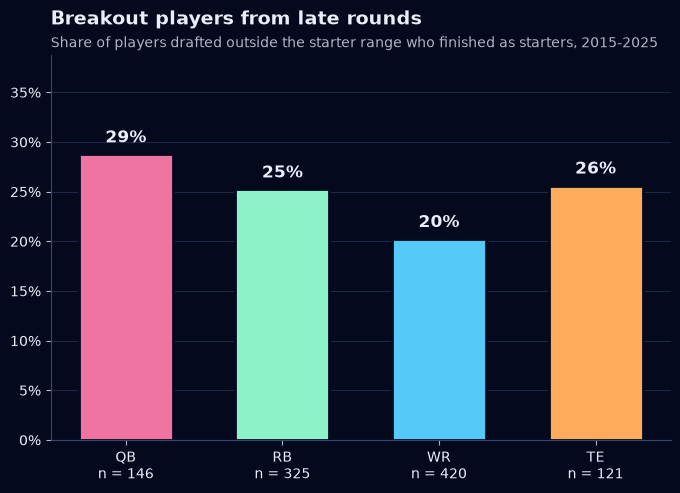

In [615]:
# Breakout rate by position
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(x, bust_summary["breakout_rate"] * 100, width=0.6, color=colors,
              edgecolor= BG, linewidth=2)
for bar, rate in zip(bars, bust_summary["breakout_rate"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
            f"{rate:.0%}", ha="center", va="bottom", color=TEXT, fontsize=12, fontweight="bold")
ax.set_xticks(x, [f"{p}\nn = {n}"
                  for p, n in zip(POS_ORDER, bust_summary["drafted_non_starters"])])
ax.set_ylim(0, bust_summary["breakout_rate"].max() * 100 + 10)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_title("Breakout players from late rounds", loc="left", pad=22,
             fontsize=14, fontweight="bold", color=TEXT)
ax.text(0, 1.02, "Share of players drafted outside the starter range who finished as starters, 2015-2025",
        transform=ax.transAxes, color=MUTED, fontsize=10)
style_axes(ax)
fig.savefig("figures/breakout_rate_by_position.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Examples for the slides
show = ["season", "player", "position", "adp", "pos_adp_rank", "pos_finish_rank", "games", "por"]

print("Biggest breakouts (largest jump from draft rank to finish rank):")
breakouts = merged[merged["breakout"]].assign(jump=lambda d: d["pos_adp_rank"] - d["pos_finish_rank"])
display(breakouts.sort_values("jump", ascending=False).head(10)[show + ["jump"]])

print("Costliest busts (earliest picks who busted):")
display(merged[merged["bust"]].sort_values("adp").head(10)[show + ["bust_type"]])

Biggest breakouts (largest jump from draft rank to finish rank):


,season,player,position,adp,pos_adp_rank,pos_finish_rank,games,por,jump
1596,2023,Kyren Williams,RB,193.0,71,7.0,12.0,80.5,64.0
363,2016,Jordan Howard,RB,197.0,62,10.0,15.0,85.5,52.0
503,2017,Alvin Kamara,RB,167.4,52,3.0,16.0,175.2,49.0
142,2015,DeAngelo Williams,RB,158.5,53,4.0,16.0,87.7,49.0
1928,2025,Wan'Dale Robinson,WR,189.3,63,14.0,16.0,37.0,49.0
689,2018,James Conner,RB,169.2,55,6.0,13.0,128.0,49.0
535,2017,Dion Lewis,RB,193.0,61,13.0,16.0,57.8,48.0
1252,2021,Amon-Ra St. Brown,WR,198.5,70,22.0,16.0,41.7,48.0
1574,2023,Nico Collins,WR,174.0,60,12.0,15.0,54.0,48.0
145,2015,Doug Baldwin,WR,162.3,56,10.0,16.0,83.2,46.0


Costliest busts (earliest picks who busted):


,season,player,position,adp,pos_adp_rank,pos_finish_rank,games,por,bust_type
1598,2024,Christian McCaffrey,RB,1.0,1,68.0,4.0,-110.1,missed time
365,2017,David Johnson,RB,1.0,1,106.0,1.0,-132.2,missed time
1428,2023,Justin Jefferson,WR,1.0,1,33.0,10.0,-4.2,missed time
1256,2022,Jonathan Taylor,RB,1.0,1,33.0,11.0,-12.1,missed time
1083,2021,Christian McCaffrey,RB,1.0,1,38.0,7.0,-21.1,missed time
904,2020,Christian McCaffrey,RB,1.0,1,54.0,3.0,-67.7,missed time
0,2015,Le'Veon Bell,RB,1.5,1,47.0,6.0,-34.5,missed time
905,2020,Saquon Barkley,RB,2.0,2,116.0,2.0,-142.7,missed time
546,2018,Le'Veon Bell,RB,2.4,2,150.0,0.0,-152.0,missed time
4,2015,Eddie Lacy,RB,4.0,4,32.0,15.0,-5.1,"played, underperformed"


Costliest busts are mainly injuries: 9 of the 10 earliest busted picks missed time, including McCaffrey 2020, 2021 and 2024, David Johnson 2017 and Jonathan Taylor 2022. Only Eddie Lacy 2015 (15 games) busted while healthy. 

Breakouts are mostly late-round RBs: Kyren Williams 2023 (RB71 → RB7), Alvin Kamara 2017 (RB52 → RB3), James Conner 2018.
QB 2025: Jayden Daniels (QB3 → QB34, 7 games), Kyler Murray and Joe Burrow all missed time, while Matthew Stafford went from QB23 to QB3.

In [617]:
# Save the final analysis dataset (all analysis columns) and a copy for the homework
FINAL_COLS = ["season", "player", "position", "adp", "round", "pos_adp_rank",
              "ppr_pts", "games", "games_missed", "ppg", "pos_finish_rank",
              "repl_pts", "por", "missed_season"]

final = merged[FINAL_COLS].sort_values(["season", "adp"]).reset_index(drop=True)

# Full analysis dataset
final.to_csv(f"data/processed/adp_analysis_{START_SEASON}_{END_SEASON}.csv", index=False)

# Homework copy: the same data, saved next to the homework files
Path("homework").mkdir(exist_ok=True)
final.to_csv(f"homework/fantasy_adp_{START_SEASON}_{END_SEASON}.csv", index=False)

print(final.shape)                       # Expect (1936, 14)
print(final.isna().sum().sum(), "missing values")   # Expect 0

(1936, 14)
0 missing values
